# 08. Multimodal Fusion — bảng số cuối cùng và Nested CV

258 participant, nhãn group, outer Stratified 6-Fold, inner 3-Fold, seed 42.
Notebook **chỉ đọc** kết quả đã chạy, không fit hay chọn lại mô hình.
Metric bảng số ở 0–1; delta ở điểm phần trăm; hình ở %. OOF gộp và mean±SD
được tách cột. SD sáu fold có train chồng lấp không phải khoảng tin cậy.
`all_selected` chọn phương pháp/tổ hợp bằng inner CV và cho phép giữ Kinematic.
Hàng đứng đầu outer summary có thiên lệch chọn hàng thắng, không phải xác nhận độc lập.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, roc_auc_score

ROOT=Path.cwd() if (Path.cwd()/'results/fusion_ablation').exists() else Path.cwd().parent
OUT=ROOT/'results/fusion_ablation'
validation=json.loads((OUT/'validation.json').read_text())
assert validation.get('numerical_validation_passed'), 'Chạy report_fusion_ablation.py trước.'
settings=json.loads((OUT/'settings.json').read_text())
summary=pd.read_csv(OUT/'nested_summary.csv')
folds=pd.read_csv(OUT/'fold_scores.csv')
oof=pd.read_csv(OUT/'nested_oof.csv')
selected=pd.read_csv(OUT/'selected_by_fold.csv')
ablation=pd.read_csv(OUT/'ablation_comparison.csv')
changes=pd.read_csv(OUT/'correction_harm.csv')
costs=pd.read_csv(OUT/'compute_costs.csv')
METHODS=['original','compact','late','adaptive']; VARIANTS=['KM','KG','KC','KMG']
LABELS={'original':'Original Early','compact':'Compact Early','late':'Late','adaptive':'Adaptive'}
COLORS={'original':'#0072B2','compact':'#E69F00','late':'#009E73','adaptive':'#CC79A7'}
core=['Kinematic_LightGBM']+[m+'__'+v for m in METHODS for v in VARIANTS]+['all_selected']
pd.set_option('display.max_columns',None)
pd.set_option('display.float_format','{:.6f}'.format)
FIG=OUT/'figures'; FIG.mkdir(exist_ok=True); manifest=[]
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none'})
def show(fig,name,description,sources):
    for ext in ('png','svg'): fig.savefig(FIG/(name+'.'+ext),dpi=180,facecolor='white')
    manifest.append(dict(name=name,description=description,sources=sources,n_participants=258,
        source_sha256={p:hashlib.sha256((OUT/p).read_bytes()).hexdigest() for p in sources},
        uncertainty='SD of six overlapping-training outer folds, not CI',
        files={ext:hashlib.sha256((FIG/(name+'.'+ext)).read_bytes()).hexdigest() for ext in ('png','svg')}))
    plt.show(); plt.close(fig)
print('OOF chỉ được tạo từ outer Test; lựa chọn dùng inner CV. Không thực hiện XAI.')

OOF chỉ được tạo từ outer Test; lựa chọn dùng inner CV. Không thực hiện XAI.


## Kết quả cuối cùng — toàn bộ bảng số Nested CV

Kinematic_LightGBM là baseline cố định cũ. Original Early dùng embedding gốc;
Compact/Late/Adaptive dùng GAF channel_concat (hậu tố adapter là đối chứng).
`single__*` là đơn nhánh chọn bằng inner CV, `equal__*` chỉ cho uniform pooling.

In [2]:
columns=['scenario','mean_raw_features','mean_features','accuracy','f1_macro','auc','balanced_accuracy',
         'mean_accuracy','std_accuracy','mean_f1_macro','std_f1_macro',
         'mean_auc','std_auc','mean_balanced_accuracy','std_balanced_accuracy',
         'delta_oof_accuracy_pp','delta_oof_f1_macro_pp','delta_oof_auc_pp']
with pd.option_context('display.max_rows',None):
    display(summary[columns].sort_values('mean_f1_macro',ascending=False).reset_index(drop=True))

,scenario,mean_raw_features,mean_features,accuracy,f1_macro,auc,balanced_accuracy,mean_accuracy,std_accuracy,mean_f1_macro,std_f1_macro,mean_auc,std_auc,mean_balanced_accuracy,std_balanced_accuracy,delta_oof_accuracy_pp,delta_oof_f1_macro_pp,delta_oof_auc_pp
0,adaptive__KC,26124.000000,5378.500000,0.856589,0.855633,0.911584,0.857860,0.856589,0.040056,0.855538,0.039689,0.910946,0.030606,0.858027,0.036333,0.775194,0.846932,0.468227
1,late__KC,26124.000000,17820.666667,0.852713,0.850958,0.917969,0.850958,0.852713,0.035013,0.850856,0.035231,0.917169,0.023722,0.851338,0.034887,0.387597,0.379437,1.106719
2,Kinematic_LightGBM,1036.000000,1027.666667,0.848837,0.847163,0.906902,0.847461,0.848837,0.032056,0.847047,0.032387,0.904027,0.031284,0.847276,0.032343,0.000000,0.000000,0.000000
3,adaptive__KG_adapter,11788.000000,1194.333333,0.841085,0.838442,0.893098,0.837063,0.841085,0.057751,0.838596,0.057047,0.896348,0.053983,0.837047,0.053953,-0.775194,-0.872121,-1.380359
4,adaptive__KMG_adapter,26124.000000,1345.500000,0.841085,0.838442,0.904773,0.837063,0.841085,0.055846,0.838516,0.055776,0.910955,0.041582,0.836896,0.054032,-0.775194,-0.872121,-0.212831
5,adaptive__KM,15372.000000,1161.166667,0.837209,0.835539,0.899544,0.836120,0.837209,0.060644,0.835558,0.060819,0.904392,0.019064,0.835946,0.059813,-1.162791,-1.162427,-0.735786
6,equal__KG_adapter,11788.000000,1123.666667,0.837209,0.833200,0.884767,0.830161,0.837209,0.053031,0.833167,0.052430,0.890481,0.057392,0.829920,0.049645,-1.162791,-1.396344,-2.213439
7,late__KM,15372.000000,1161.166667,0.833333,0.831488,0.900943,0.831773,0.833333,0.061382,0.831589,0.061491,0.904367,0.019318,0.831779,0.060505,-1.550388,-1.567555,-0.595926
8,late__KMG_adapter,26124.000000,1359.833333,0.833333,0.831201,0.907145,0.830921,0.833333,0.053875,0.831216,0.054090,0.906919,0.027540,0.830865,0.053116,-1.550388,-1.596272,0.024324
9,late__KG_adapter,11788.000000,1162.333333,0.833333,0.830892,0.894132,0.830070,0.833333,0.057751,0.831024,0.057039,0.899978,0.055060,0.829952,0.054019,-1.550388,-1.627148,-1.276984


## Ablation theo nhánh và phương pháp — bảng số

KMG so với KM đo thêm GAF; KMG so với KG đo thêm MOMENT. Mỗi quy trình được chọn
cấu hình riêng trong Train; đây không phải hiệu ứng nhân quả của một nhánh cố định.
Late so với equal đo giá trị của việc cho phép học trọng số. Δ ở điểm phần trăm.

In [3]:
with pd.option_context('display.max_rows',None): display(ablation)

,method,scenario,reference,effect,delta_oof_accuracy_pp,delta_mean_accuracy_pp,delta_oof_f1_macro_pp,delta_mean_f1_macro_pp,delta_oof_auc_pp,delta_mean_auc_pp,delta_oof_balanced_accuracy_pp,delta_mean_balanced_accuracy_pp
0,original,original__KM,Kinematic_LightGBM,M,-9.302326,-9.302326,-9.492642,-9.647911,-7.211919,-6.782037,-9.583460,-9.474161
1,original,original__KG,Kinematic_LightGBM,G,-9.302326,-9.302326,-9.492642,-9.665352,-5.910611,-5.287948,-9.583460,-9.539950
2,original,original__KC,Kinematic_LightGBM,C,-5.426357,-5.426357,-5.644113,-5.769175,-4.287017,-4.375795,-5.831560,-5.734649
3,original,original__KMG,original__KM,G given KM,-0.775194,-0.775194,-0.739876,-0.769733,0.419580,0.940440,-0.699301,-0.812357
4,original,original__KMG,original__KG,M given KG,-0.775194,-0.775194,-0.739876,-0.752291,-0.881727,-0.553649,-0.699301,-0.746568
5,compact,compact__KM,Kinematic_LightGBM,M,-5.038760,-5.038760,-5.078162,-5.146385,-2.280328,-1.828121,-5.056248,-5.055301
6,compact,compact__KG,Kinematic_LightGBM,G,-5.813953,-5.813953,-5.861310,-5.905699,-3.277592,-2.589944,-5.840681,-5.767067
7,compact,compact__KC,Kinematic_LightGBM,C,-1.550388,-1.550388,-1.596272,-1.668756,-1.252660,-1.204551,-1.653998,-1.663012
8,compact,compact__KMG,compact__KM,G given KM,1.162791,1.162791,1.126551,1.154002,-0.006081,1.134312,1.048951,1.137649
9,compact,compact__KMG,compact__KG,M given KG,1.937984,1.937984,1.909698,1.913316,0.991183,1.896135,1.833384,1.849415


## Lựa chọn từng fold và các trường hợp fallback

In [4]:
with pd.option_context('display.max_rows',None):
    display(selected[selected.scenario.isin(core)].reset_index(drop=True))

,scenario,fold,candidate,method,variant,n_features,inner_f1_macro,inner_accuracy,fallback_to_kinematic,combiner
0,Kinematic_LightGBM,0,K_only,baseline,K,1028,0.808229,0.813902,True,{}
1,original__KM,0,original__KM__LightGBM,original,KM,15372,0.749771,0.758216,False,{}
2,original__KG,0,original__KG__LightGBM,original,KG,11788,0.679995,0.688250,False,{}
3,original__KC,0,original__KC__LightGBM,original,KC,26124,0.723909,0.735198,False,{}
4,original__KMG,0,original__KMG__LightGBM,original,KMG,26124,0.705570,0.716223,False,{}
5,compact__KM,0,compact__KM__none__pca_var99__LightGBM,compact,KM,1231,0.783738,0.790558,False,{}
6,compact__KG,0,compact__KG__none__pca_var95__LightGBM,compact,KG,1217,0.795016,0.799883,False,{}
7,compact__KC,0,compact__KC__none__pca_var99__LightGBM,compact,KC,1232,0.773577,0.781364,False,{}
8,compact__KMG,0,compact__KMG__none__anova_64__anova_256__Logis...,compact,KMG,1348,0.771638,0.776930,False,{}
9,late__KM,0,late__KM__K__none__LightGBM__M__anova_64__Logi...,late,KM,1092,0.827707,0.832486,False,"{""kind"": ""late"", ""ridge"": 0.1, ""budget"": 0.5, ..."


## Kết quả theo fold — bảng số đầy đủ

In [5]:
with pd.option_context('display.max_rows',None):
    display(folds[folds.scenario.isin(core)].sort_values(['scenario','fold']).reset_index(drop=True))

,scenario,fold,candidate,n_features,n_features_pipeline,n_features_raw,accuracy,f1_macro,f1_weighted,f1_binary,auc,balanced_accuracy
0,Kinematic_LightGBM,0,K_only,1028,1028,1036,0.837209,0.836856,0.837386,0.844444,0.895652,0.838043
1,Kinematic_LightGBM,1,K_only,1027,1027,1036,0.860465,0.858553,0.860465,0.875000,0.960526,0.858553
2,Kinematic_LightGBM,2,K_only,1028,1028,1036,0.837209,0.835788,0.837565,0.851064,0.901316,0.837719
3,Kinematic_LightGBM,3,K_only,1028,1028,1036,0.906977,0.905702,0.906977,0.916667,0.899123,0.905702
4,Kinematic_LightGBM,4,K_only,1028,1028,1036,0.813953,0.811404,0.813953,0.833333,0.864035,0.811404
5,Kinematic_LightGBM,5,K_only,1027,1027,1036,0.837209,0.833977,0.836671,0.857143,0.903509,0.832237
6,adaptive__KC,0,adaptive__KC__K__none__LightGBM__C__pca_var99_...,1232,1232,26124,0.860465,0.859783,0.860465,0.869565,0.913043,0.859783
7,adaptive__KC,1,adaptive__KC__K__none__LightGBM__C__pca_var99_...,1230,1230,26124,0.860465,0.858553,0.860465,0.875000,0.964912,0.858553
8,adaptive__KC,2,adaptive__KC__K__none__LightGBM__C__none__Logi...,26116,26116,26124,0.790698,0.790698,0.790698,0.790698,0.899123,0.801535
9,adaptive__KC,3,adaptive__KC__K__none__LightGBM__C__pca_var99_...,1231,1231,26124,0.906977,0.905702,0.906977,0.916667,0.899123,0.905702


## So sánh bốn phương pháp, cùng tổ hợp nhánh

Điểm là mean F1 macro sáu outer fold, thanh là SD (không phải CI).
Đường baseline cố định và cùng thang 0–100%; dấu vuông nhỏ là pooled OOF F1.

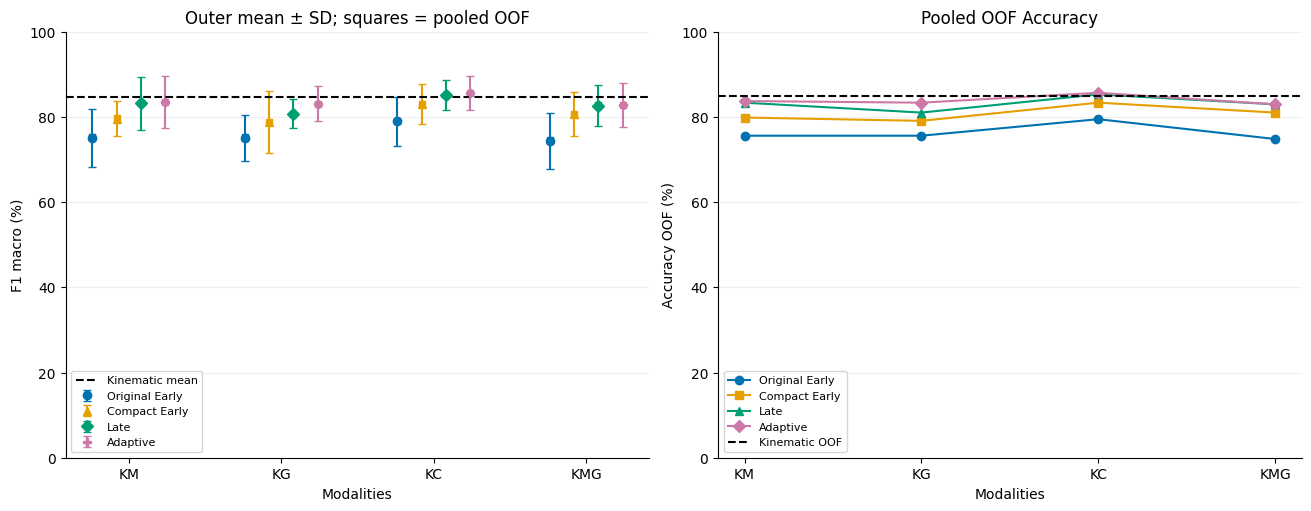

In [6]:
base=summary.set_index('scenario').loc['Kinematic_LightGBM']
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
x=np.arange(4)
for j,m in enumerate(METHODS):
    frame=summary.set_index('scenario').loc[[m+'__'+v for v in VARIANTS]]
    pos=x+(j-1.5)*.16
    axes[0].errorbar(pos,100*frame.mean_f1_macro,yerr=100*frame.std_f1_macro,fmt=['o','^','D','P'][j],capsize=3,
                     color=COLORS[m],label=LABELS[m])
    axes[0].scatter(pos,100*frame.f1_macro,marker='s',s=15,color=COLORS[m])
    axes[1].plot(x,100*frame.accuracy,marker=['o','s','^','D'][j],color=COLORS[m],label=LABELS[m])
axes[0].axhline(base.mean_f1_macro*100,color='black',linestyle='--',label='Kinematic mean')
axes[1].axhline(base.accuracy*100,color='black',linestyle='--',label='Kinematic OOF')
for ax in axes: ax.set(xticks=x,xticklabels=VARIANTS,ylim=(0,100),xlabel='Modalities'); ax.grid(axis='y',alpha=.2)
axes[0].set_ylabel('F1 macro (%)'); axes[0].set_title('Outer mean ± SD; squares = pooled OOF')
axes[1].set_ylabel('Accuracy OOF (%)'); axes[1].set_title('Pooled OOF Accuracy')
axes[0].legend(fontsize=8,loc='lower left'); axes[1].legend(fontsize=8,loc='lower left')
show(fig,'nested_comparison','Four fusion methods and fixed Kinematic baseline; fold SD and pooled OOF.', ['nested_summary.csv'])

## Chênh lệch từng fold so với Kinematic

Sáu điểm là sáu outer Test folds; các Train folds chồng lấp. Không thêm kiểm định độc lập.

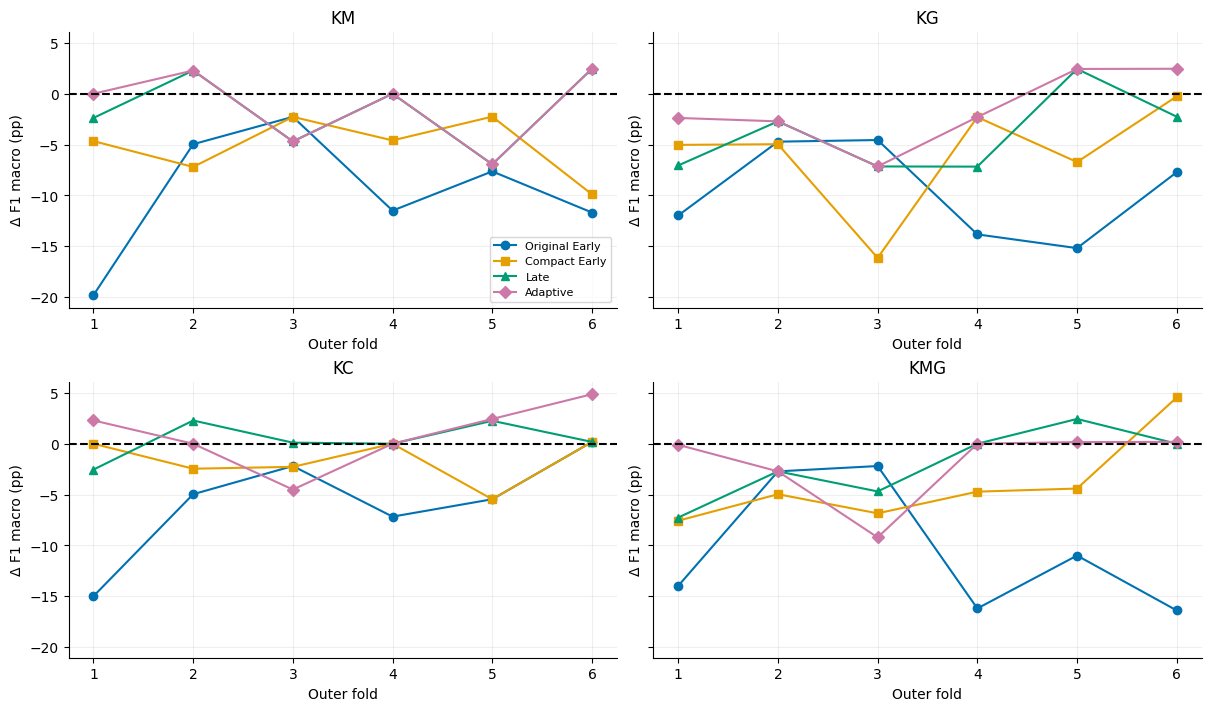

In [7]:
fig,axes=plt.subplots(2,2,figsize=(12,7),layout='constrained',sharey=True)
k=folds[folds.scenario=='Kinematic_LightGBM'].set_index('fold').sort_index()
for ax,v in zip(axes.ravel(),VARIANTS):
    for j,m in enumerate(METHODS):
        f=folds[folds.scenario==m+'__'+v].set_index('fold').sort_index()
        ax.plot(np.arange(1,7),(f.f1_macro-k.f1_macro)*100,marker=['o','s','^','D'][j],color=COLORS[m],label=LABELS[m])
    ax.axhline(0,color='black',linestyle='--'); ax.set(title=v,xlabel='Outer fold',ylabel='Δ F1 macro (pp)',xticks=np.arange(1,7))
    ax.grid(alpha=.2)
axes[0,0].legend(fontsize=8)
show(fig,'paired_outer_folds','Paired outer fold F1 difference from fixed Kinematic.', ['fold_scores.csv'])

## ROC từ OOF — xem quy trình chọn phương pháp

Chỉ hiển thị baseline và all_selected (lựa chọn bằng inner CV), không chọn đường ROC đẹp nhất.
Xác suất pooled đến từ sáu mô hình khác nhau; AUC gộp có thể khác mean AUC từng fold.

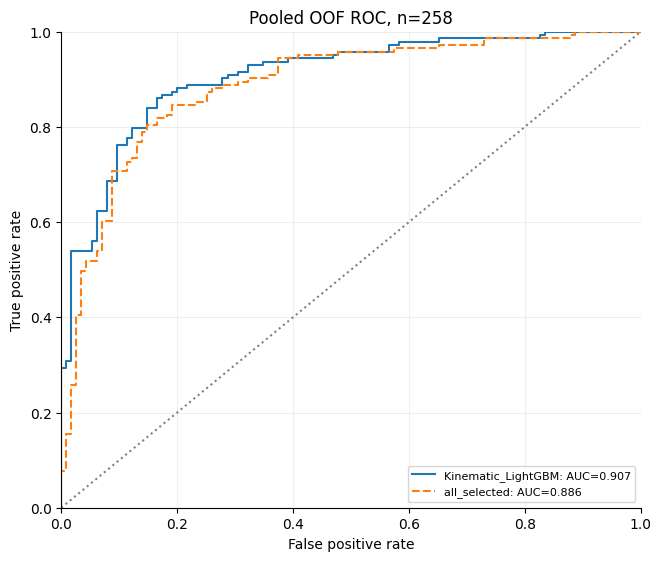

In [8]:
fig,ax=plt.subplots(figsize=(6.5,5.5),layout='constrained')
for name,style in [('Kinematic_LightGBM','-'),('all_selected','--')]:
    frame=oof[oof.scenario==name]
    fpr,tpr,_=roc_curve(frame.label,frame.probability)
    ax.plot(fpr,tpr,linestyle=style,label=f'{name}: AUC={roc_auc_score(frame.label,frame.probability):.3f}')
ax.plot([0,1],[0,1],':',color='gray'); ax.set(xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1),title='Pooled OOF ROC, n=258')
ax.legend(fontsize=8); ax.grid(alpha=.2)
show(fig,'oof_roc','ROC for fixed baseline and nested method selection, no post-hoc curve selection.', ['nested_oof.csv'])

## Sửa đúng và gây hại — số người so với Kinematic

Số dương: baseline sai, Fusion đúng. Số âm: baseline đúng, Fusion sai. Không dùng các ca Test
này để điều chỉnh gate. Tệp prediction_changes.csv có xác suất và dự đoán từng người.

,scenario,corrected,harmed,same_correct,same_wrong
0,Kinematic_LightGBM,0,0,219,39
1,original__KM,12,36,183,27
2,original__KG,14,38,181,25
3,original__KC,14,28,191,25
4,original__KMG,13,39,180,26
5,compact__KM,6,19,200,33
6,compact__KG,13,28,191,26
7,compact__KC,12,16,203,27
8,compact__KMG,15,25,194,24
9,late__KM,5,9,210,34


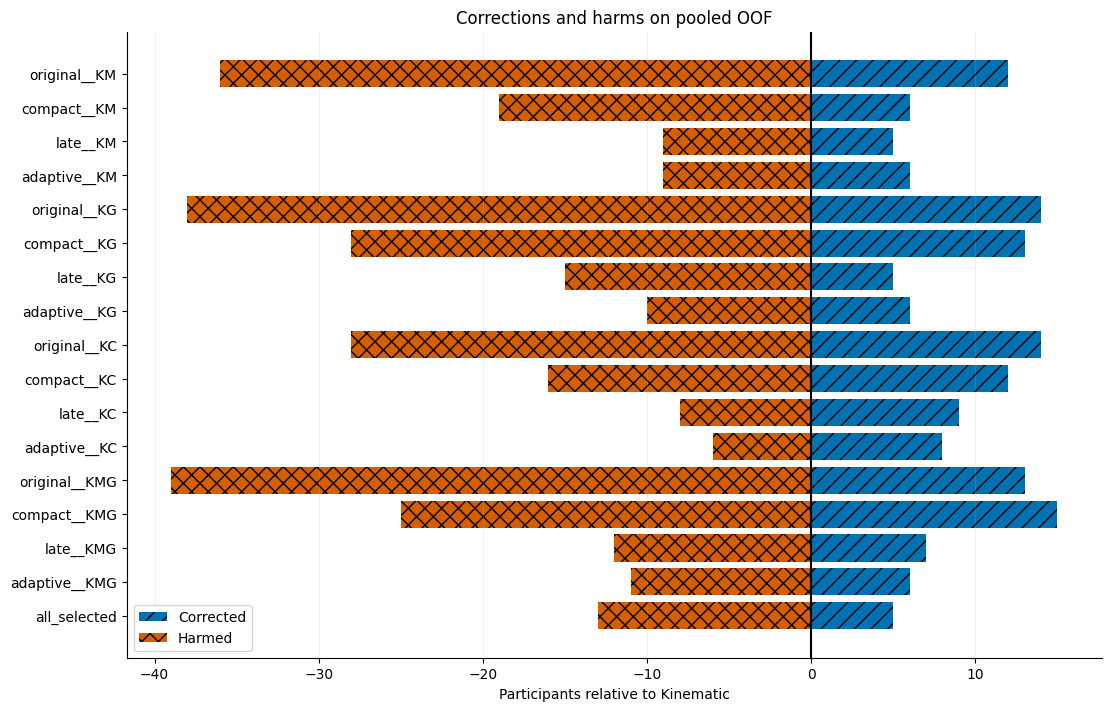

In [9]:
display(changes[changes.scenario.isin(core)].reset_index(drop=True))
names=[m+'__'+v for v in VARIANTS for m in METHODS]+['all_selected']
frame=changes.set_index('scenario').loc[names]
fig,ax=plt.subplots(figsize=(11,7),layout='constrained')
positions=np.arange(len(frame))
ax.barh(positions,frame.corrected,color='#0072B2',label='Corrected',hatch='//')
ax.barh(positions,-frame.harmed,color='#D55E00',label='Harmed',hatch='xx')
ax.axvline(0,color='black'); ax.set(yticks=positions,yticklabels=names,xlabel='Participants relative to Kinematic',title='Corrections and harms on pooled OOF')
ax.invert_yaxis(); ax.legend(); ax.grid(axis='x',alpha=.2)
show(fig,'correction_harm','Counts corrected/harmed against Kinematic across all prespecified main scenarios.', ['correction_harm.csv'])

## Giá trị thêm từng nhánh và GAF adapter

Heatmap thể hiện Δ OOF F1; ô nào âm được giữ nguyên, không lọc kết quả giảm.

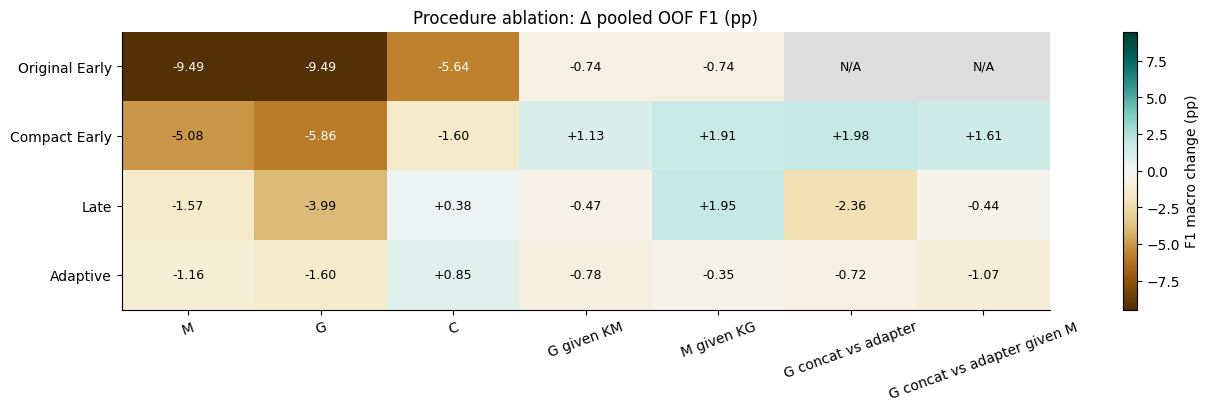

In [10]:
effects=['M','G','C','G given KM','M given KG','G concat vs adapter','G concat vs adapter given M']
table=ablation.pivot_table(index='method',columns='effect',values='delta_oof_f1_macro_pp').reindex(index=METHODS,columns=effects)
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
limit=max(1,float(np.nanmax(np.abs(table.to_numpy()))))
cmap=plt.get_cmap('BrBG').copy(); cmap.set_bad('#dddddd')
im=ax.imshow(table.to_numpy(),cmap=cmap,vmin=-limit,vmax=limit,aspect='auto')
for i in range(len(METHODS)):
    for j in range(len(effects)):
        val=table.iloc[i,j]; ax.text(j,i,'N/A' if pd.isna(val) else f'{val:+.2f}',ha='center',va='center',fontsize=9,
                                   color='white' if pd.notna(val) and abs(val)>limit*.55 else 'black')
ax.set(xticks=range(len(effects)),xticklabels=effects,yticks=range(4),yticklabels=[LABELS[m] for m in METHODS],title='Procedure ablation: Δ pooled OOF F1 (pp)')
ax.tick_params(axis='x',rotation=20); fig.colorbar(im,ax=ax,label='F1 macro change (pp)')
show(fig,'modality_ablation','Matched procedure contrasts including negative effects and low-cost GAF adapter.', ['ablation_comparison.csv'])

## Adaptive: trọng số khi gate hoạt động và fallback từng fold

Khi gate tắt, trọng số Kinematic bằng 1. Hình dưới dùng trọng số hiệu dụng khi gate bật;
fallback K_only cũng bằng 1. Đây không phải giải thích XAI hoặc importance nhân quả.

,variant,fold,gate_active_fraction,fallback
0,KM,0,0.139535,False
1,KM,1,1.000000,False
2,KM,2,0.093023,False
3,KM,3,0.046512,False
4,KM,4,1.000000,False
5,KM,5,0.162791,False
6,KG,0,0.139535,False
7,KG,1,1.000000,False
8,KG,2,0.186047,False
9,KG,3,0.046512,False


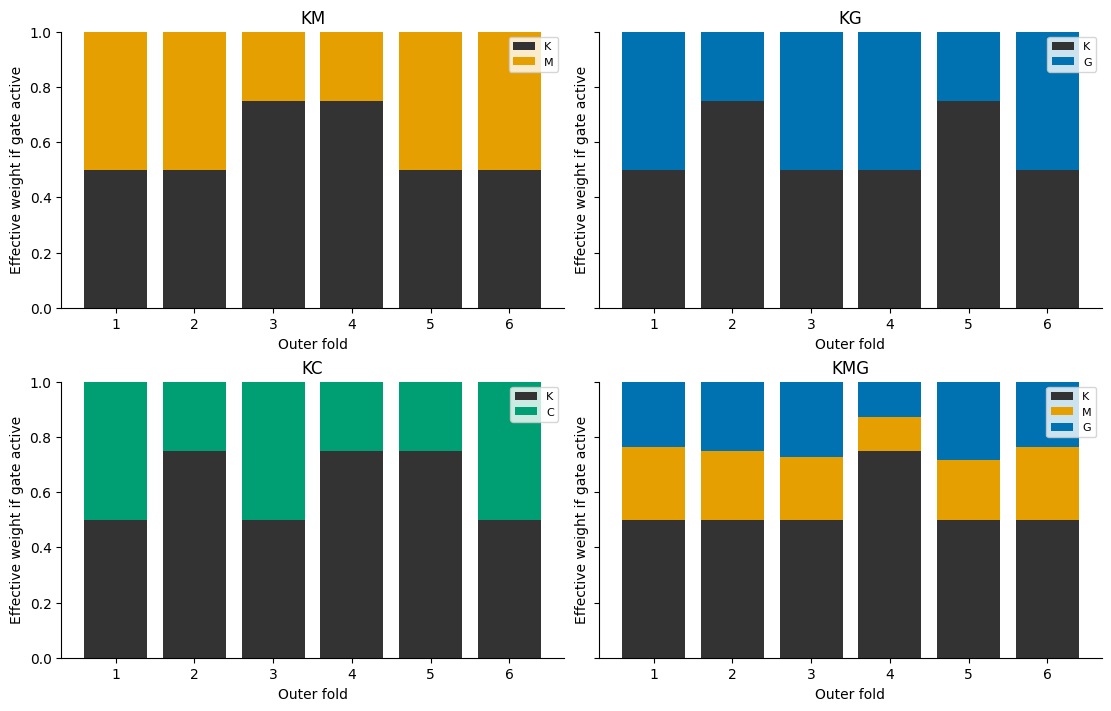

In [11]:
palette={'K':'#333333','M':'#E69F00','G':'#0072B2','C':'#009E73'}
fig,axes=plt.subplots(2,2,figsize=(11,7),layout='constrained',sharey=True)
gate_rows=[]
for ax,v in zip(axes.ravel(),VARIANTS):
    sub=selected[selected.scenario=='adaptive__'+v].sort_values('fold')
    weights={b:np.zeros(6) for b in palette}
    for j,row in enumerate(sub.itertuples()):
        c=settings['grid'][row.candidate]
        if row.candidate=='K_only': weights['K'][j]=1
        else:
            comb=json.loads(row.combiner); weights['K'][j]=1-comb['budget']
            for b,w in zip(c['branches'][1:],comb['weights']): weights[b][j]=comb['budget']*w
        record=json.loads((OUT/'folds'/f'fold_{row.fold}.json').read_text())['results']['adaptive__'+v]
        gate_rows.append(dict(variant=v,fold=row.fold,gate_active_fraction=float(np.mean(record.get('gate_active',[False]*43))),fallback=row.candidate=='K_only'))
    bottom=np.zeros(6)
    for b,w in weights.items():
        if np.any(w): ax.bar(np.arange(1,7),w,bottom=bottom,color=palette[b],label=b); bottom+=w
    ax.set(title=v,ylim=(0,1),xticks=np.arange(1,7),xlabel='Outer fold',ylabel='Effective weight if gate active'); ax.legend(fontsize=8)
display(pd.DataFrame(gate_rows))
show(fig,'adaptive_weights','Gated convex contribution and Kinematic fallback in each outer fold.', ['selected_by_fold.csv','settings.json'])

## Số chiều và chi phí tìm kiếm đã đo

Tổng workload có chia sẻ bank và nhiều ứng viên; không phải thời gian end-to-end hay latency.
Trục số chiều dùng log10. Không chạy encoder/GPU trong thực nghiệm này.

,stage,measured_fit_transform_seconds
0,outer_0_inner_0,76.202213
1,outer_0_inner_0_crossfit_0,5.731583
2,outer_0_inner_0_crossfit_1,5.756805
3,outer_0_inner_0_crossfit_2,5.622748
4,outer_0_inner_1,77.913243
...,...,...
73,outer_5_inner_2,75.015226
74,outer_5_inner_2_crossfit_0,5.894013
75,outer_5_inner_2_crossfit_1,8.137706
76,outer_5_inner_2_crossfit_2,5.724350


,scenario,confidence_low,confidence_high,n,corrected,harmed
0,Kinematic_LightGBM,0.000000,0.100000,21,0,0
1,Kinematic_LightGBM,0.100000,0.200000,22,0,0
2,Kinematic_LightGBM,0.200000,0.300000,17,0,0
3,Kinematic_LightGBM,0.300000,0.400000,33,0,0
4,Kinematic_LightGBM,0.400000,0.500000,165,0,0
...,...,...,...,...,...,...
165,all_selected,0.000000,0.100000,21,4,4
166,all_selected,0.100000,0.200000,22,0,3
167,all_selected,0.200000,0.300000,17,0,1
168,all_selected,0.300000,0.400000,33,1,3


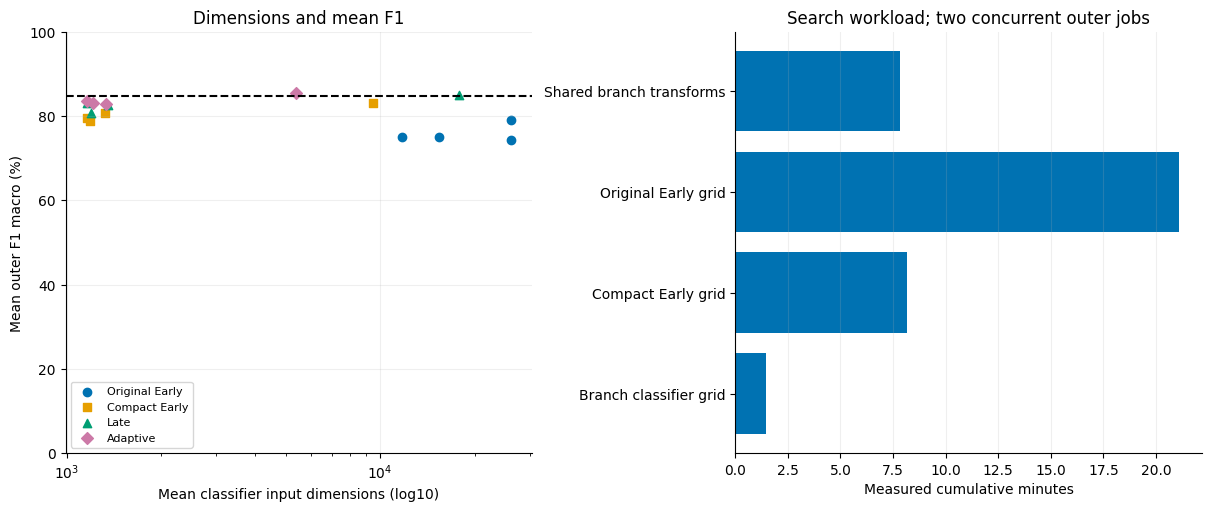

In [12]:
display(costs.groupby('stage',sort=False).agg(measured_fit_transform_seconds=('seconds','sum')).reset_index())
display(pd.read_csv(OUT/'confidence_ablation.csv'))
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for m in METHODS:
    frame=summary[summary.scenario.isin([m+'__'+v for v in VARIANTS])]
    axes[0].scatter(frame.mean_features,frame.mean_f1_macro*100,label=LABELS[m],color=COLORS[m],marker={'original':'o','compact':'s','late':'^','adaptive':'D'}[m])
axes[0].axhline(base.mean_f1_macro*100,color='black',linestyle='--'); axes[0].set(xscale='log',ylim=(0,100),xlabel='Mean classifier input dimensions (log10)',ylabel='Mean outer F1 macro (%)',title='Dimensions and mean F1')
axes[0].legend(fontsize=8); axes[0].grid(alpha=.2)
def family(s):
    if s.startswith('bank_'): return 'Shared branch transforms'
    if s.startswith('original__'): return 'Original Early grid'
    if s.startswith('compact__'): return 'Compact Early grid'
    return 'Branch classifier grid'
sums=costs.assign(family=costs.component.map(family)).groupby('family').seconds.sum()/60
axes[1].barh(sums.index,sums.values,color='#0072B2'); axes[1].set(xlabel='Measured cumulative minutes',title='Search workload; two concurrent outer jobs')
axes[1].grid(axis='x',alpha=.2)
show(fig,'compute_cost','Classifier dimensions versus F1 and cumulative measured search components; excludes encoders and meta fitting.', ['nested_summary.csv','compute_costs.csv'])

## Kiểm chứng và kết luận

Đọc REPORT_VI.md để phân biệt cải thiện mô tả với bằng chứng xác nhận. Thiết kế tham khảo
kết quả cũ trên cùng cohort, nên cần external holdout cho kết luận tổng quát.
Notebook không chọn cấu hình mới và không triển khai XAI.

In [13]:
(FIG/'manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
display(pd.DataFrame([{k:v for k,v in validation.items() if k!='numerical_artifact_sha256'}]))
print((OUT/'REPORT_VI.md').read_text(encoding='utf-8').split('## Thiết kế')[0])

,complete,stage,numerical_validation_passed,n_subjects,seed,outer_folds,inner_folds,meta_crossfit_folds,candidates,scenarios,outer_records,stages,original_artifacts_unchanged,baseline_oof_exact,inner_predictions_replayed,outer_checkpoints_replayed,participant_leakage_checks_passed,validation_seconds
0,False,numerical_validation_passed,True,258,42,6,3,3,287,34,6,78,1016,True,True,True,True,72.241595


# Multimodal Fusion — Nested CV và Ablation Study

## Kết quả và trạng thái

**Có cải thiện mô tả ở cả F1 trung bình fold và Accuracy OOF so với Kinematic.** Cấu hình Fusion có mean F1 cao nhất trong bốn phương pháp/tổ hợp chính là
`adaptive__KC`: OOF Accuracy 85.66%, F1 macro 85.56%,
ROC-AUC 91.16%; Δ OOF F1 +0.85 điểm phần trăm.
Đây là hàng đứng đầu sau khi xem kết quả, có thiên lệch chọn hàng thắng. `all_selected` là quy trình
chọn giữa các phương pháp/tổ hợp chính hoàn toàn bằng inner CV, cần đọc cùng hàng này.

Baseline chính **Kinematic nguyên chiều + LightGBM**, giữ nguyên tham số cũ:
OOF Accuracy **84.88%**, F1 macro **84.72%**,
ROC-AUC **90.69%**. Dự đoán và xác suất tái fit khớp baseline cũ trong tolerance 1e-12.
Kết quả mới không thay thế baseline. Chỉ `validation.json complete=true` xác nhận hoàn tất sau
kiểm tra notebook, hình, checkpoint, OOF, nguồn dữ liệu và tests.


